# Laboratorio 3 — Data Augmentation

En este notebook se aplican las transformaciones de augmentation acordadas en `docs/report/03_seleccion_modelos.md` (rotación de hasta ±15°, zoom leve, y variación de brillo/contraste — sin flips) sobre el conjunto de entrenamiento, y se reentrena la arquitectura de **CNN 2** (el mejor modelo de la Fase 2) para ver si el augmentation mejora el desempeño sobre el conjunto de prueba. También se responde el ejercicio 7 sobre por qué el flip horizontal no se usa para este dataset.

## Setup y verificaciones

### Imports

In [5]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
#keras = tf.keras
#layers = keras.layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)


TensorFlow: 2.18.1


### Definicion de rutas

In [6]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


### Carga de datos

In [7]:
X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

classes = pd.read_csv(PROCESSED_DIR / "classes.csv")["label"].tolist()

print("Datos cargados correctamente.")


Datos cargados correctamente.


## Pipeline de augmentation

Se implementa como un bloque de capas de Keras que se agrega al inicio del modelo (alternativa equivalente a usar `ImageDataGenerator`). Estas capas **solo transforman las imágenes durante el entrenamiento**; en inferencia (`model.predict`) Keras las desactiva automáticamente, así que no hace falta ningún manejo especial para evaluar sobre validación o prueba.

- `RandomRotation(15/360)`: rotación de hasta ±15°, tal como se definió en el plan de procesamiento.
- `RandomZoom(0.1)`: zoom leve, hasta un 10% de acercamiento/alejamiento.
- `RandomBrightness(0.15)` y `RandomContrast(0.15)`: variación leve de brillo y contraste, para simular distintas condiciones de iluminación.

**No se incluye `RandomFlip`** (ni horizontal ni vertical): la justificación se desarrolla en la respuesta al ejercicio 7, al final de este notebook.

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(15 / 360),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),
], name="augmentation")


### Visualización de ejemplos aumentados

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [26.245941..27.254322].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [4.470964..5.5234175].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [17.500223..18.42002].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [37.758606..38.732216].


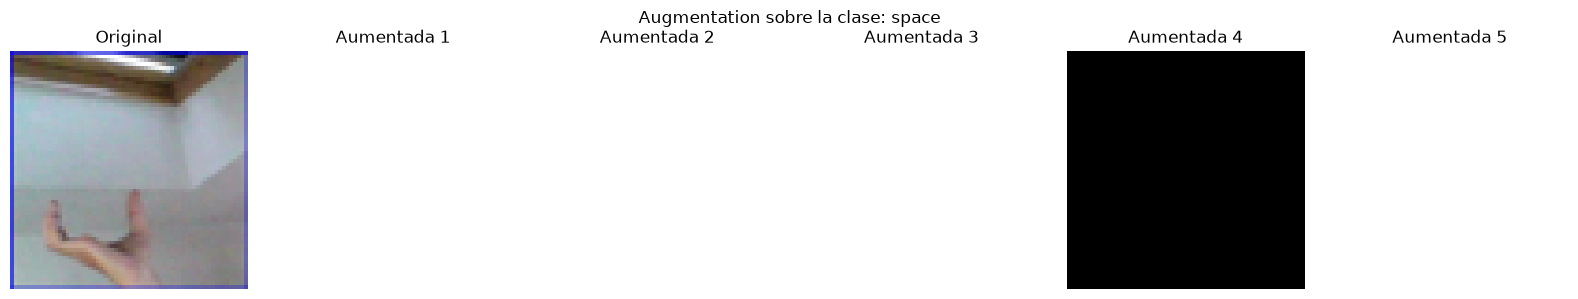

In [9]:
ejemplo = X_train[0:1]

fig, axes = plt.subplots(1, 6, figsize=(16, 3))

axes[0].imshow(ejemplo[0])
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(1, 6):
    aumentada = data_augmentation(ejemplo, training=True)
    axes[i].imshow(aumentada[0].numpy())
    axes[i].set_title(f"Aumentada {i}")
    axes[i].axis("off")

plt.suptitle(f"Augmentation sobre la clase: {classes[y_train[0]]}")
plt.tight_layout()
plt.show()


## Reentrenamiento de CNN 2 con augmentation

Se reconstruye exactamente la misma arquitectura de CNN 2 usada en `02_modelos_cnn.ipynb` (configuración base, learning rate 0.0005), agregando el bloque de `data_augmentation` justo después de la capa de entrada, y se entrena desde cero sobre el conjunto de entrenamiento.

In [10]:
def build_cnn2_augmented(learning_rate=0.0005):
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),

        data_augmentation,

        # Bloque convolucional 1
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Bloque convolucional 2
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Bloque convolucional 3
        layers.Conv2D(128, kernel_size=(3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Clasificacion
        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(29, activation="softmax")
    ])

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn2_augmented = build_cnn2_augmented(learning_rate=0.0005)
cnn2_augmented.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,310,685 (5.00 MB)

 Trainable params: 1,310,237 (5.00 MB)

 Non-trainable params: 448 (1.75 KB)

### Entrenamiento

In [12]:
BATCH_SIZE = 32
EPOCHS = 15

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_cnn2_augmented = cnn2_augmented.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15


2026-08-09 21:49:55.229963: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


445/445 ━━━━━━━━━━━━━━━━━━━━ 32s 52ms/step - accuracy: 0.0349 - loss: 16.7834 - val_accuracy: 0.0273 - val_loss: 4.9115
Epoch 2/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 21s 47ms/step - accuracy: 0.0342 - loss: 16.3957 - val_accuracy: 0.0358 - val_loss: 4.5837
Epoch 3/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 22s 50ms/step - accuracy: 0.0359 - loss: 10.5251 - val_accuracy: 0.0443 - val_loss: 5.6865
Epoch 4/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.0330 - loss: 7.2650 - val_accuracy: 0.0394 - val_loss: 3.8398
Epoch 5/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.0365 - loss: 5.1755 - val_accuracy: 0.0338 - val_loss: 3.6755
Epoch 6/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.0360 - loss: 4.1325 - val_accuracy: 0.0342 - val_loss: 3.5308
Epoch 7/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.0342 - loss: 3.6981 - val_accuracy: 0.0342 - val_loss: 3.5993
Epoch 8/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.0338 - loss: 3.5728 - val_accu

### Visualizacion de entrenamiento

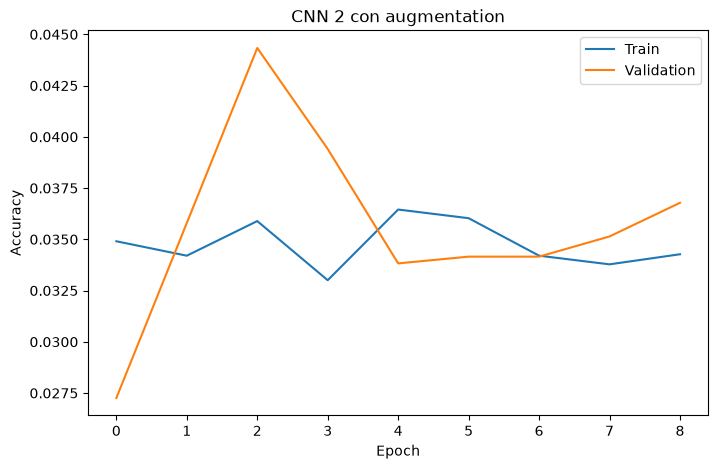

In [13]:
def plot_training_history(history, title):
    history_df = pd.DataFrame(history.history)

    plt.figure(figsize=(8, 5))

    plt.plot(history_df["accuracy"], label="Train")
    plt.plot(history_df["val_accuracy"], label="Validation")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.show()


plot_training_history(
    history_cnn2_augmented,
    "CNN 2 con augmentation"
)


## Evaluación antes/después de augmentation

Como "antes" se carga y evalúa el `models/best_cnn.keras` (CNN 2 sin augmentation) — se vuelve a correr sobre el test set únicamente para inferencia, no se reentrena. Como "después" se usa la CNN 2 recién entrenada con augmentation.

In [14]:
def evaluate_model(model, X_test, y_test, model_name):
    y_prob = model.predict(X_test, batch_size=32, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred, average="macro", zero_division=0)

    print(model_name)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")

    return {
        "Modelo": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall
    }, y_pred


In [15]:
cnn2_original = keras.models.load_model(MODELS_DIR / "best_cnn.keras")

metrics_antes, pred_antes = evaluate_model(
    cnn2_original,
    X_test,
    y_test,
    "CNN 2 (sin augmentation)"
)


CNN 2 (sin augmentation)
Accuracy:  0.7350
Precision: 0.8243
Recall:    0.7350


In [16]:
metrics_despues, pred_despues = evaluate_model(
    cnn2_augmented,
    X_test,
    y_test,
    "CNN 2 (con augmentation)"
)


CNN 2 (con augmentation)
Accuracy:  0.0388
Precision: 0.0026
Recall:    0.0388


### Tabla comparativa antes/después

In [17]:
augmentation_df = pd.DataFrame([metrics_antes, metrics_despues])
augmentation_df


,Modelo,Accuracy,Precision,Recall
0,CNN 2 (sin augmentation),0.734975,0.824330,0.734975
1,CNN 2 (con augmentation),0.038752,0.002585,0.038752


### Matrices de confusión antes/después

Útil para ver si el augmentation ayuda específicamente en las letras visualmente parecidas detectadas en el EDA (R/U/V/W, A/E, S/Y).

In [18]:
def plot_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(14, 14))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False)
    ax.set_title(title)

    plt.tight_layout()
    plt.show()


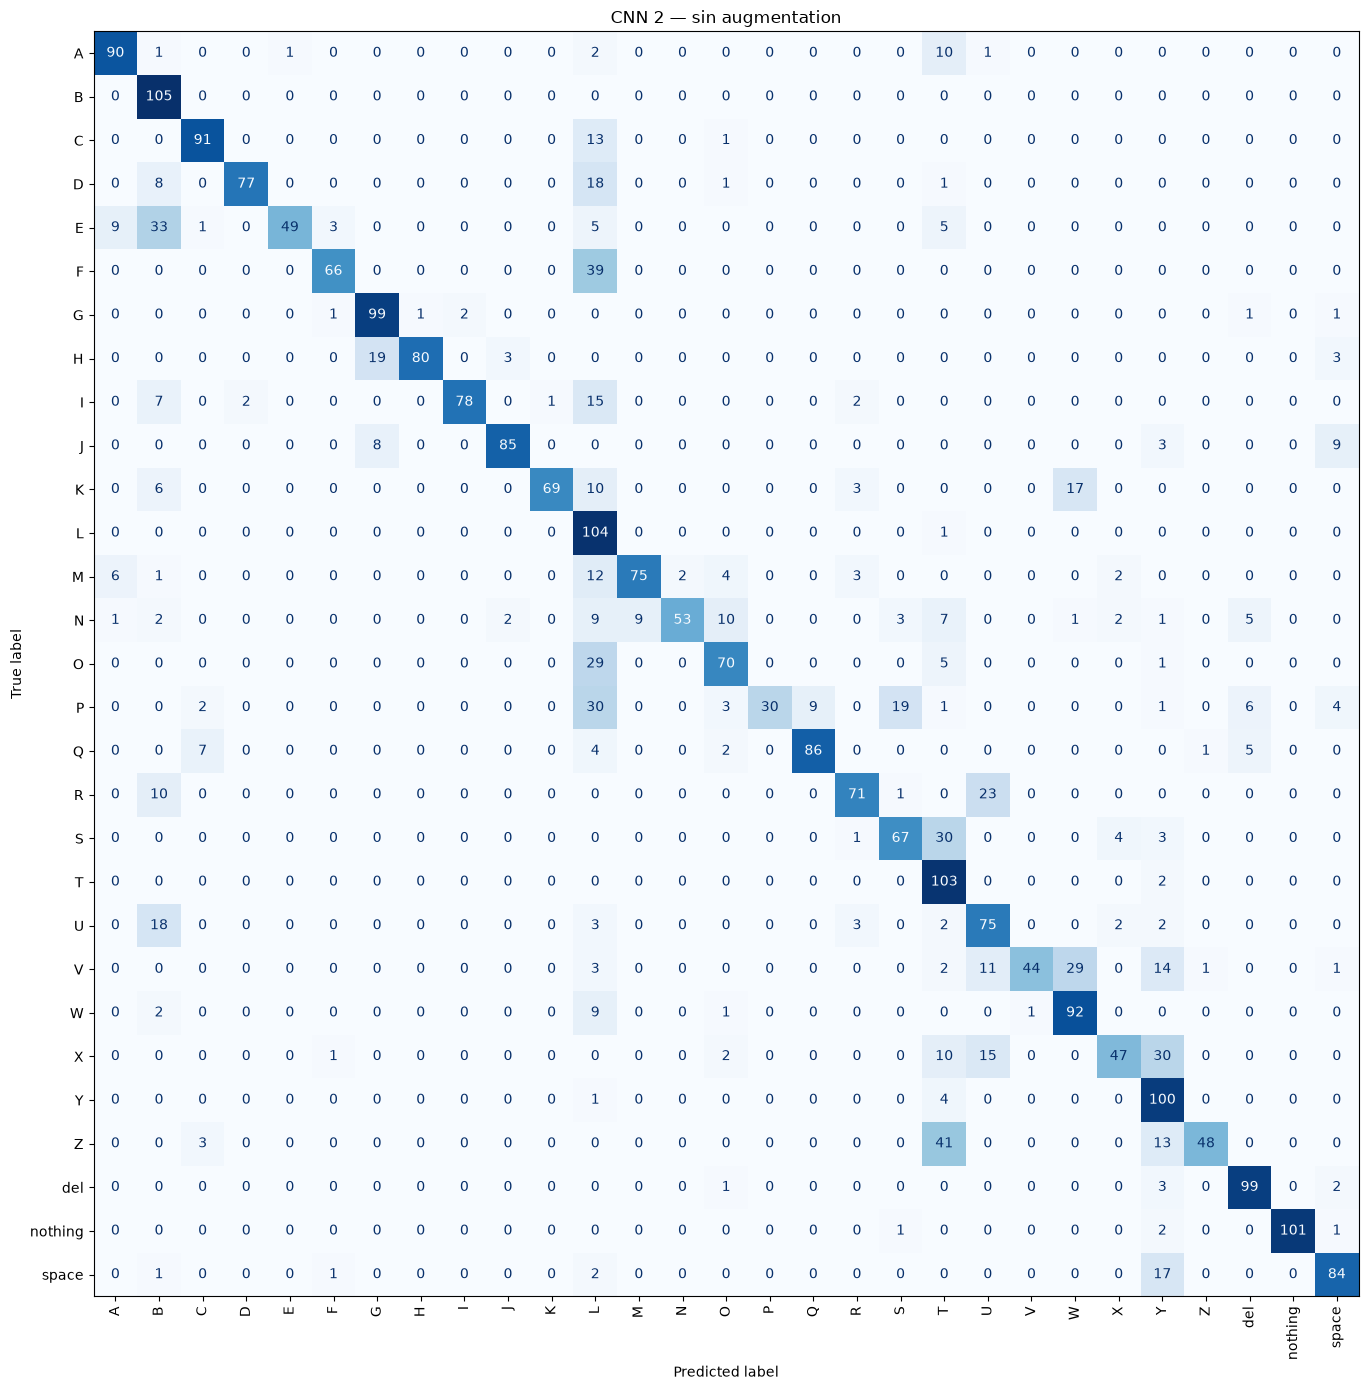

In [19]:
plot_confusion_matrix(y_test, pred_antes, classes, "CNN 2 — sin augmentation")


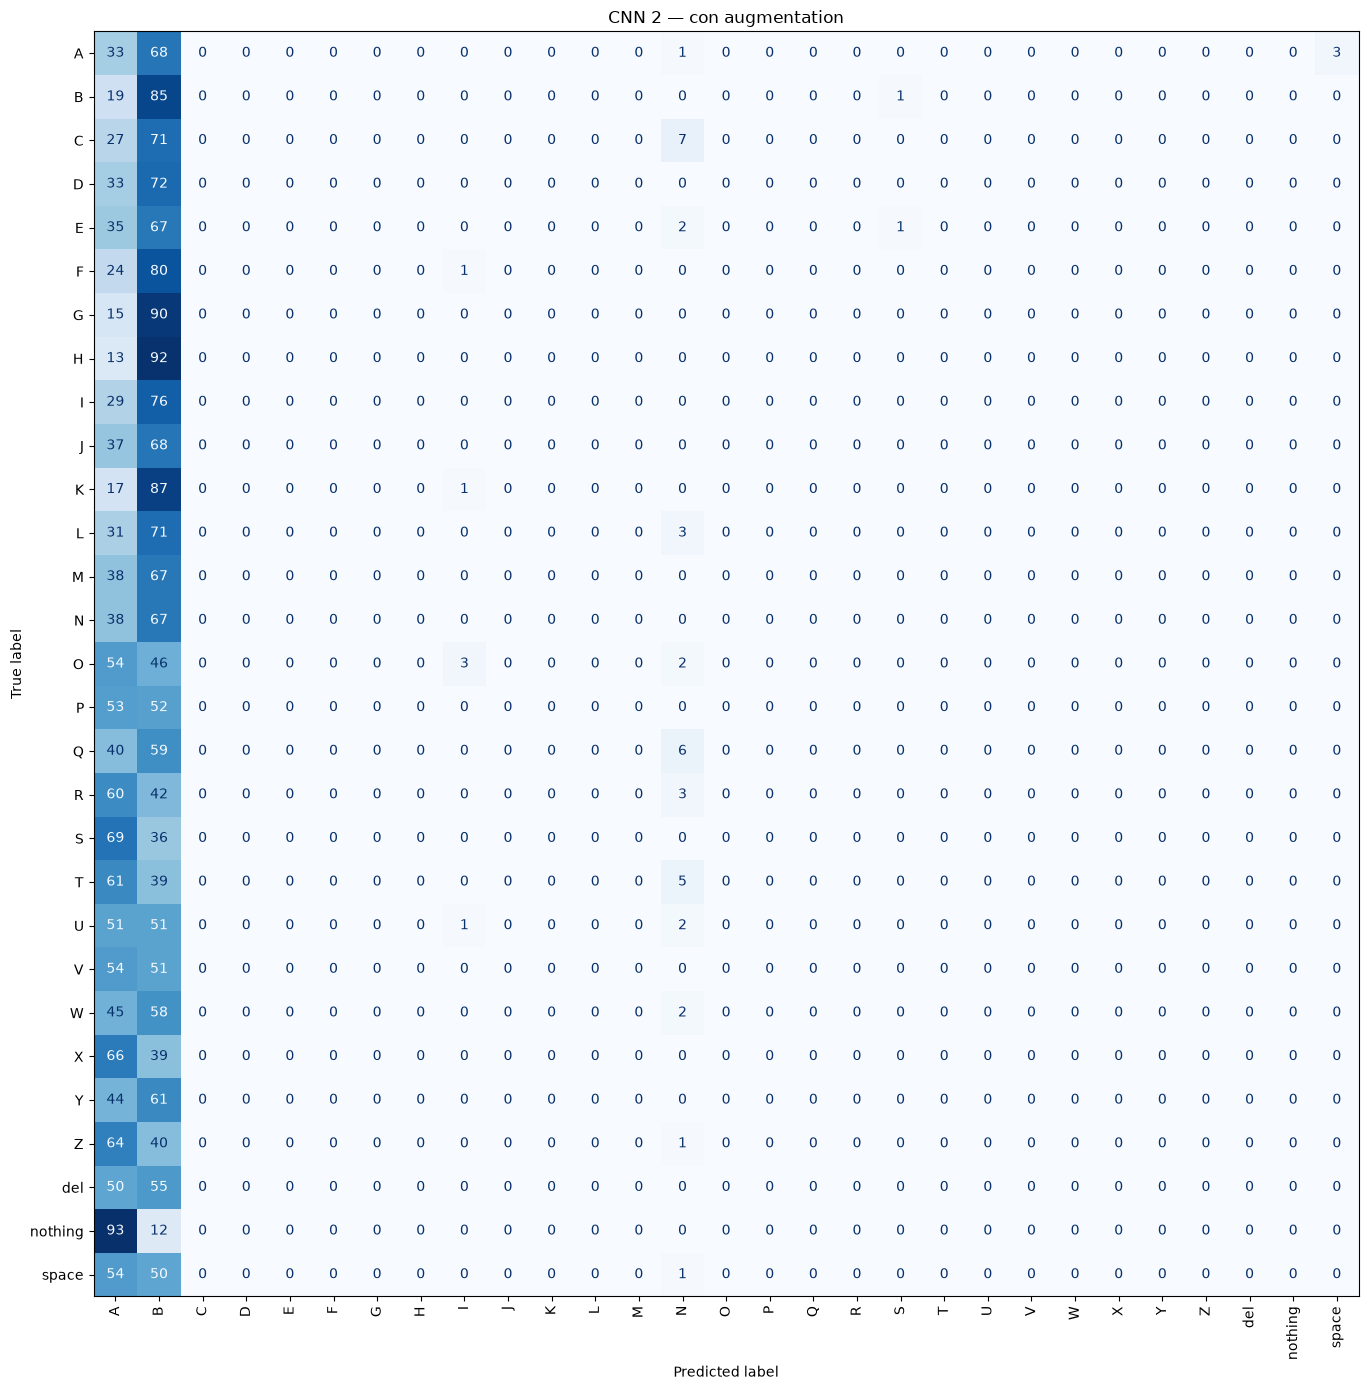

In [20]:
plot_confusion_matrix(y_test, pred_despues, classes, "CNN 2 — con augmentation")


### Guardar métricas y modelo

El modelo aumentado se guarda aparte, en `models/best_cnn_augmented.keras`, **sin sobrescribir** `models/best_cnn.keras` (ese archivo es el entregable ya cerrado de la Fase 2). Si tras comparar las métricas el modelo con augmentation resulta mejor, se puede decidir en equipo si vale la pena promoverlo como el nuevo `best_cnn.keras`.

In [21]:
augmentation_df.to_csv(RESULTS_DIR / "metrics_augmentation.csv", index=False)

augmented_path = MODELS_DIR / "best_cnn_augmented.keras"
cnn2_augmented.save(augmented_path)

print(f"Métricas guardadas en: {RESULTS_DIR / 'metrics_augmentation.csv'}")
print(f"Modelo guardado en: {augmented_path}")


Métricas guardadas en: ../results/metrics_augmentation.csv
Modelo guardado en: ../models/best_cnn_augmented.keras


### Conclusión

Sin augmentation, CNN 2 obtuvo **73.50%** de accuracy sobre el conjunto de prueba; con augmentation obtuvo **3.88%**, es decir, el accuracy empeoró en **69.62 puntos porcentuales**. Precision macro pasó de **82.43%** a **0.26%**, y recall macro de **73.50%** a **3.88%**. Por esto parece ser el conjunto de datos ya era suficientemente grande como para que augmentation mejorara el rsultado. 

In [23]:
mejora_accuracy = (metrics_despues["Accuracy"] - metrics_antes["Accuracy"]) * 100
direccion = "mejoró" if mejora_accuracy > 0 else ("empeoró" if mejora_accuracy < 0 else "no cambió")

print(mejora_accuracy, direccion)


-69.6223316912972 empeoró


## Ejercicio 7 — Flips y transformaciones válidas para señas

**¿Por qué un flip horizontal podría cambiar el significado de una seña en vez de solo aumentar los datos?**

En la mayoría de las tareas de visión por computadora un flip horizontal es una transformación segura porque el objeto sigue siendo el mismo objeto visto en espejo (un perro sigue siendo un perro). Con el alfabeto ASL esto deja de ser cierto: la forma de la mano codifica directamente la letra, y esa forma depende de la orientación relativa de los dedos y de qué lado de la mano queda al frente de la cámara. Voltear la imagen horizontalmente puede convertir la seña de una letra en la seña real de otra letra distinta, o en una configuración de mano que no corresponde a ninguna seña válida del alfabeto. Por ejemplo, entre los pares que ya se identificaron como visualmente parecidos en el EDA (R/U, U/V, V/W), buena parte de lo que los distingue es precisamente la posición relativa de los dedos; un flip horizontal puede acercar artificialmente una letra a otra del mismo grupo, o generar una imagen que el modelo aprenda con una etiqueta que ya no describe lo que la mano realmente está mostrando.

Un flip vertical tiene un problema similar: invierte la orientación de la mano respecto a la muñeca y al antebrazo, algo que no ocurre de forma natural cuando una persona firma frente a una cámara fija sostenida frente a su cuerpo. En ambos casos, la transformación deja de representar una variación realista de cómo un usuario real de la app de SignBridge haría esa seña frente a su cámara — y ese es justamente el objetivo del augmentation: generar variaciones plausibles, no imágenes que confundan la etiqueta.

**¿Qué transformaciones sí tienen sentido para señas, y cuáles no?**

Sí tienen sentido las transformaciones que perturban la imagen sin cambiar la forma relativa de los dedos entre sí, porque simulan variaciones reales de cómo alguien firma frente a una cámara: pequeñas rotaciones (la mano no siempre está perfectamente alineada con el encuadre), zoom leve (distintas distancias entre la mano y la cámara) y variaciones de brillo/contraste (distintas condiciones de iluminación en el cuarto del usuario). Son las tres transformaciones que se implementaron arriba.

No tienen sentido los flips horizontal y vertical, por lo explicado arriba. Tampoco tendría sentido un recorte (`crop`) demasiado agresivo que llegue a cortar dedos fuera del encuadre, ni distorsiones geométricas fuertes (shear extremo, deformaciones no rígidas) que alteren la posición relativa de los dedos entre sí, ya que esa posición relativa es exactamente la señal que el modelo necesita aprender para distinguir una letra de otra.